# Studio risultati: FedHydra vs Fed2RC 

Ordine logico: **carico → rimuovo i duplicati → controllo la copertura dei dataset → confronto solo su dataset comuni**.
k = kernel
g = gruppi
r = round (1 equivale a -r 0)

## 1. 

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

file_dict = {
    'Rocket_2048':     '../fed2rc_wvc_results_1seed_2048kernel.csv',
    'Rocket_512k_1r':  '../fed2rc_wvc_results_1s_512k_1r.csv',
    'Rocket_512k':     '../fed2rc_wvc_results_1s_512k.csv',
    'Hydra_1k_64g_1r': '../fedhydra_results_1s_1k_64g_1r.csv',
    'Hydra_1k_64g':    '../fedhydra_results_1s_1k_64g.csv',
    'Hydra_2k_32g':    '../fedhydra_results_1s_2k_32g.csv',
    'Hydra_2k_64g':    '../fedhydra_results_1s_2k_64g.csv',
    'Hydra_4k_16g':    '../fedhydra_results_1s_4k_16g.csv',
    'Hydra_4k_64g':    '../fedhydra_results_1s_4k_64g.csv',
    'Hydra_8k_16g':    '../fedhydra_results_1s_8k_16g.csv',
    'Hydra_8k_2g':     '../fedhydra_results_1s_8k_2g.csv',
    'Hydra_8k_32g':    '../fedhydra_results_1s_8k_32g.csv',
    'Hydra_8k_64g_1r': '../fedhydra_results_1s_8k_64g_1r.csv',
    'Hydra_8k_64g':    '../fedhydra_results_1s_8k_64g.csv',
    'Hydra_8k_8g':     '../fedhydra_results_1s_8k_8g.csv',
}

EXCLUDE_MODELS = []

N_HYDRA_TOP = 2

METRICS = ['Test_Accuracy', 'Test_F1', 'Rounds_to_Converge']

frames = []
for model, path in file_dict.items():
    if model in EXCLUDE_MODELS:
        continue
    try:
        d = pd.read_csv(path)
    except FileNotFoundError:
        print(f'File non trovato: {path}')
        continue
    d['Model'] = model
    d['Family'] = 'Rocket' if model.startswith('Rocket') else 'Hydra'
    frames.append(d)

raw = pd.concat(frames, ignore_index=True)
if 'Seed' not in raw.columns:
    raw['Seed'] = -1
raw['Seed'] = raw['Seed'].fillna(-1)

print(f'Righe caricate: {len(raw)}  |  Modelli: {raw.Model.nunique()}  |  Dataset: {raw.Dataset.nunique()}')

Righe caricate: 68  |  Modelli: 15  |  Dataset: 4


## 2. Duplicati

`fedhydra.py` scrive il CSV in modalità append (`mode='a'`): **ogni rilancio aggiunge righe** invece di sostituirle.
Se non si eliminano, la stessa configurazione conta più volte nelle medie e può comparire più volte nelle classifiche.
Tengo l'**ultima** riga per ogni (Modello, Dataset, Seed), cioè l'ultima run eseguita.

In [ ]:
key = ['Model', 'Dataset', 'Seed']

dup = raw.groupby(key).size().rename('n_righe').reset_index()
dup = dup[dup.n_righe > 1]
print(f'Combinazioni (Modello, Dataset, Seed) duplicate: {len(dup)}')

if len(dup):
    chk = raw.merge(dup[key], on=key)
    display(chk.sort_values(key)[key + METRICS])

df = raw.drop_duplicates(subset=key, keep='last').copy()
print(f'Righe dopo la deduplicazione: {len(df)} (rimosse {len(raw) - len(df)})')

# un solo valore per (Modello, Dataset): media sui seed
per_ds = (df.groupby(['Family', 'Model', 'Dataset'], as_index=False)[METRICS].mean())

Combinazioni (Modello, Dataset, Seed) duplicate: 7


,Model,Dataset,Seed,Test_Accuracy,Test_F1,Rounds_to_Converge
7,Hydra_1k_64g,Car,42,0.9167,0.9179,2
11,Hydra_1k_64g,Car,42,0.6500,0.6446,2
8,Hydra_1k_64g,Coffee,42,1.0000,1.0000,2
12,Hydra_1k_64g,Coffee,42,1.0000,1.0000,3
9,Hydra_1k_64g,Computers,42,0.7120,0.7231,4
13,Hydra_1k_64g,Computers,42,0.3920,0.4685,4
10,Hydra_1k_64g,EOGHorizontalSignal,42,0.5939,0.5906,2
14,Hydra_1k_64g,EOGHorizontalSignal,42,0.3425,0.3127,3
0,Rocket_2048,Car,42,0.8833,0.8734,4
1,Rocket_2048,Car,42,0.8833,0.8734,4


Righe dopo la deduplicazione: 60 (rimosse 8)


## 3. Controllo se ci sono tutti i ds

Una media calcolata su dataset diversi **non è confrontabile**: un modello senza i dataset difficili
sembra migliore solo perché non è stato testato lì. Le celle vuote (`NaN`) qui sotto sono i buchi.

In [42]:
acc_pivot = per_ds.pivot(index='Dataset', columns='Model', values='Test_Accuracy')
display(acc_pivot)

all_datasets = set(per_ds.Dataset)
missing = {m: sorted(all_datasets - set(g.Dataset)) for m, g in per_ds.groupby('Model')}
missing = {m: v for m, v in missing.items() if v}

if missing:
    print('\nModelli con dataset mancanti (limitano il confronto):')
    for m, v in missing.items():
        print(f'  {m}: mancano {v}')
else:
    print('\nTutti i modelli hanno tutti i dataset.')

common_datasets = sorted(set.intersection(*[set(g.Dataset) for _, g in per_ds.groupby('Model')]))
print(f'\nDataset presenti in TUTTI i modelli ({len(common_datasets)}): {common_datasets}')

Model,Hydra_1k_64g,Hydra_1k_64g_1r,Hydra_2k_32g,Hydra_2k_64g,Hydra_4k_16g,Hydra_4k_64g,Hydra_8k_16g,Hydra_8k_2g,Hydra_8k_32g,Hydra_8k_64g,Hydra_8k_64g_1r,Hydra_8k_8g,Rocket_2048,Rocket_512k,Rocket_512k_1r
Dataset,,,,,,,,,,,,,,,
Car,0.6500,0.6167,0.8333,0.8500,0.8000,0.9000,0.8833,0.8167,0.9167,0.9167,0.9167,0.8167,0.9000,0.8833,0.9000
Coffee,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.9643,1.0000,1.0000,1.0000,1.0000,0.9286,0.9286,1.0000
Computers,0.3920,0.4000,0.6920,0.6880,0.7120,0.6960,0.7080,0.7120,0.7080,0.7120,0.6960,0.7200,0.7880,0.7400,0.7760
EOGHorizontalSignal,0.3425,0.3287,0.5884,0.5525,0.5718,0.5884,0.5718,0.5138,0.5856,0.5939,0.6022,0.5221,0.5359,0.5552,0.5663



Tutti i modelli hanno tutti i dataset.

Dataset presenti in TUTTI i modelli (4): ['Car', 'Coffee', 'Computers', 'EOGHorizontalSignal']


## 4. Funzione di confronto

Tutti i confronti usano **solo i dataset comuni** e riportano `N_datasets` per verificarlo.
`Avg_Rank` è il rango medio per accuratezza (1 = migliore): non dipende dalla scala del dataset.

In [43]:
def summarize(models, datasets):
    sub = per_ds[per_ds.Model.isin(models) & per_ds.Dataset.isin(datasets)].copy()
    sub['Rank'] = sub.groupby('Dataset')['Test_Accuracy'].rank(ascending=False, method='average')
    out = (sub.groupby(['Family', 'Model'])
              .agg(Test_Accuracy=('Test_Accuracy', 'mean'),
                   Test_F1=('Test_F1', 'mean'),
                   Rounds=('Rounds_to_Converge', 'mean'),
                   Avg_Rank=('Rank', 'mean'),
                   N_datasets=('Dataset', 'nunique'))
              .reset_index())
    return out.sort_values(['Test_Accuracy', 'Test_F1'], ascending=False).reset_index(drop=True)

all_models = sorted(per_ds.Model.unique())

## 5. Classifica generale 

In [44]:
ranking = summarize(all_models, common_datasets)
display(ranking)

,Family,Model,Test_Accuracy,Test_F1,Rounds,Avg_Rank,N_datasets
0,Rocket,Rocket_512k_1r,0.8106,0.8069,0.0000,5.3750,4
1,Hydra,Hydra_8k_64g,0.8056,0.8079,2.5000,4.1250,4
2,Hydra,Hydra_8k_64g_1r,0.8037,0.8055,0.0000,5.0000,4
3,Hydra,Hydra_8k_32g,0.8026,0.8052,2.7500,5.5000,4
4,Hydra,Hydra_4k_64g,0.7961,0.7953,3.0000,6.3750,4
5,Hydra,Hydra_8k_16g,0.7908,0.7942,2.2500,7.2500,4
6,Rocket,Rocket_2048,0.7881,0.7832,3.5000,7.8750,4
7,Hydra,Hydra_2k_32g,0.7784,0.7828,3.7500,8.0000,4
8,Rocket,Rocket_512k,0.7768,0.7765,3.0000,8.5000,4
9,Hydra,Hydra_2k_64g,0.7726,0.7781,3.5000,9.6250,4


## 6. Top 3 per ogni dataset 

In [45]:
for ds in sorted(per_ds.Dataset.unique()):
    top = (per_ds[per_ds.Dataset == ds]
           .sort_values(['Test_Accuracy', 'Test_F1'], ascending=False)
           .head(3))
    print(f"\n{'=' * 50}\n{ds.upper()}\n{'=' * 50}")
    print(top[['Model', 'Test_Accuracy', 'Test_F1', 'Rounds_to_Converge']].to_string(index=False))


CAR
          Model  Test_Accuracy  Test_F1  Rounds_to_Converge
   Hydra_8k_32g         0.9167   0.9179              3.0000
   Hydra_8k_64g         0.9167   0.9179              2.0000
Hydra_8k_64g_1r         0.9167   0.9179              0.0000

COFFEE
          Model  Test_Accuracy  Test_F1  Rounds_to_Converge
   Hydra_1k_64g         1.0000   1.0000              3.0000
Hydra_1k_64g_1r         1.0000   1.0000              0.0000
   Hydra_2k_32g         1.0000   1.0000              3.0000

COMPUTERS
         Model  Test_Accuracy  Test_F1  Rounds_to_Converge
   Rocket_2048         0.7880   0.7969              2.0000
Rocket_512k_1r         0.7760   0.7863              0.0000
   Rocket_512k         0.7400   0.7601              2.0000

EOGHORIZONTALSIGNAL
          Model  Test_Accuracy  Test_F1  Rounds_to_Converge
Hydra_8k_64g_1r         0.6022   0.5963              0.0000
   Hydra_8k_64g         0.5939   0.5906              2.0000
   Hydra_2k_32g         0.5884   0.5964              4.0000

## 7. Heatmap accuratezza (modelli × dataset)

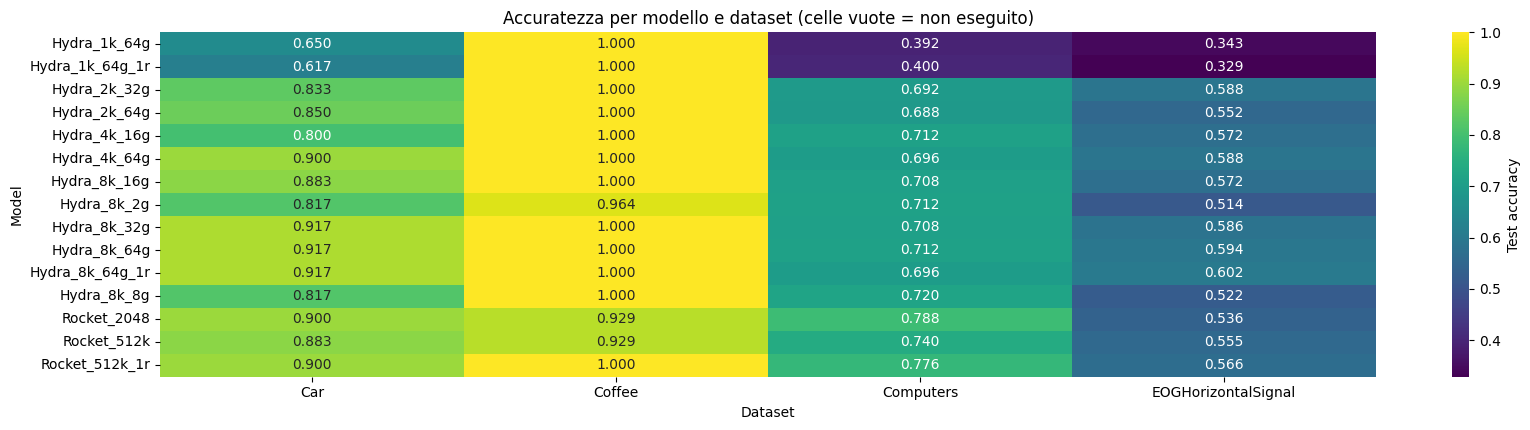

In [46]:
plt.figure(figsize=(1.0 * len(all_models) + 2, 0.6 * len(acc_pivot) + 2))
sns.heatmap(acc_pivot.T, annot=True, fmt='.3f', cmap='viridis', cbar_kws={'label': 'Test accuracy'})
plt.title('Accuratezza per modello e dataset (celle vuote = non eseguito)')
plt.tight_layout()
plt.show()

## 8. Confronto finale: migliori Hydra vs Rocket

I migliori Hydra sono scelti con la classifica della sezione 5.

In [47]:
top_hydra = ranking[ranking.Family == 'Hydra'].head(N_HYDRA_TOP).Model.tolist()
rocket_models = ranking[ranking.Family == 'Rocket'].Model.tolist()
final_models = top_hydra + rocket_models

print(f'Hydra selezionati: {top_hydra}')
print(f'Rocket: {rocket_models}')
print(f'Dataset usati: {common_datasets}\n')

final = summarize(final_models, common_datasets)
display(final)

detail = (per_ds[per_ds.Model.isin(final_models) & per_ds.Dataset.isin(common_datasets)]
          .pivot(index='Dataset', columns='Model', values='Test_Accuracy')[final.Model.tolist()])
print('\nAccuratezza per dataset:')
display(detail)

Hydra selezionati: ['Hydra_8k_64g', 'Hydra_8k_64g_1r']
Rocket: ['Rocket_512k_1r', 'Rocket_2048', 'Rocket_512k']
Dataset usati: ['Car', 'Coffee', 'Computers', 'EOGHorizontalSignal']



,Family,Model,Test_Accuracy,Test_F1,Rounds,Avg_Rank,N_datasets
0,Rocket,Rocket_512k_1r,0.8106,0.8069,0.0000,2.6250,4
1,Hydra,Hydra_8k_64g,0.8056,0.8079,2.5000,2.3750,4
2,Hydra,Hydra_8k_64g_1r,0.8037,0.8055,0.0000,2.3750,4
3,Rocket,Rocket_2048,0.7881,0.7832,3.5000,3.5000,4
4,Rocket,Rocket_512k,0.7768,0.7765,3.0000,4.1250,4



Accuratezza per dataset:


Model,Rocket_512k_1r,Hydra_8k_64g,Hydra_8k_64g_1r,Rocket_2048,Rocket_512k
Dataset,,,,,
Car,0.9000,0.9167,0.9167,0.9000,0.8833
Coffee,1.0000,1.0000,1.0000,0.9286,0.9286
Computers,0.7760,0.7120,0.6960,0.7880,0.7400
EOGHorizontalSignal,0.5663,0.5939,0.6022,0.5359,0.5552
